# 01 - Data Cleaning: MRL Eye Dataset (Driver Drowsiness Detection)

 step 1 Goal: turn the raw MRL Eye image folder into a clean


In [3]:
import os, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

sns.set_theme(style='whitegrid')
pd.set_option('display.width', 160)

DATA_DIR = os.environ.get('MRL_DIR', '../data/raw/mrl')   # folder with the MRL images (subfolders allowed)
PROC_DIR = '../data/processed'
IMG_DIR  = '../images'
os.makedirs(PROC_DIR, exist_ok=True); os.makedirs(IMG_DIR, exist_ok=True)

def savefig(name):
    plt.savefig(os.path.join(IMG_DIR, name), dpi=150, bbox_inches='tight')

cleaning_log = []  
def log(step, removed, remaining):
    cleaning_log.append(dict(step=step, rows_removed=int(removed), rows_remaining=int(remaining)))
    print(f'{step}: removed {removed}, remaining {remaining}')

In [5]:
COLS = ['subject', 'image_id', 'gender', 'glasses', 'eye_state', 'reflections', 'lighting', 'sensor']
rows = []
for p in paths:
    stem = os.path.splitext(os.path.basename(p))[0].strip()
    parts = stem.split('_')
    rec = {'path': p, 'n_fields': len(parts)}
    if len(parts) == 8:
        rec.update(dict(zip(COLS, parts)))
    rows.append(rec)
meta = pd.DataFrame(rows)

# consistent formats: lower-case subject IDs, numeric types for the coded fields
meta['subject'] = meta['subject'].str.lower().str.strip()
NUM = COLS[1:]
for c in NUM:
    meta[c] = pd.to_numeric(meta[c], errors='coerce')

print('Filenames with wrong number of fields:', (meta.n_fields != 8).sum())
print('\nMissing values per column:'); print(meta[COLS].isna().sum().to_string())
meta[meta[COLS].isna().any(axis=1)].head()

Filenames with wrong number of fields: 0

Missing values per column:
subject        0
image_id       0
gender         0
glasses        0
eye_state      0
reflections    0
lighting       0
sensor         0


,path,n_fields,subject,image_id,gender,glasses,eye_state,reflections,lighting,sensor


In [6]:
# validity of every coded field
ALLOWED = {'gender': {0, 1}, 'glasses': {0, 1}, 'eye_state': {0, 1},
           'reflections': {0, 1, 2}, 'lighting': {0, 1}, 'sensor': {1, 2, 3}}
valid = (meta.n_fields == 8) & meta.subject.str.match(r'^s\d+$', na=False) & meta[NUM].notna().all(axis=1)
for c, ok in ALLOWED.items():
    valid &= meta[c].isin(ok)

print('Invalid / malformed rows:', (~valid).sum())
print(meta.loc[~valid, ['path']].assign(file=lambda d: d.path.map(os.path.basename)).file.head(10).to_string())

before = len(meta)
meta = meta[valid].copy().reset_index(drop=True)
for c in NUM: meta[c] = meta[c].astype(int)
log('Dropped malformed / missing / invalid-value filenames', before - len(meta), len(meta))

Invalid / malformed rows: 0
Series([], )
Dropped malformed / missing / invalid-value filenames: removed 0, remaining 84898


## 3. Create the target label and inspect every image

In [ ]:
meta['closed'] = 1 - meta['eye_state']

def inspect(p):
    rec = {'readable': True}
    try:
        with open(p, 'rb') as f: raw = f.read()
        rec['file_md5'] = hashlib.md5(raw).hexdigest()
        rec['file_kb'] = len(raw) / 1024
        with Image.open(p) as im:
            rec['mode'], rec['format'] = im.mode, im.format
            rec['width'], rec['height'] = im.size
            g = np.asarray(im.convert('L'))
        rec['mean_intensity'] = float(g.mean())
        rec['std_intensity'] = float(g.std())
        rec['pixel_md5'] = hashlib.md5(g.tobytes() + str(g.shape).encode()).hexdigest()
    except Exception as e:
        rec['readable'] = False
        rec['error'] = str(e)[:80]
    return rec

info = pd.DataFrame([inspect(p) for p in tqdm(meta.path)])
meta = pd.concat([meta, info], axis=1)
print('Unreadable / corrupt images:', (~meta.readable).sum())


100%|██████████| 84898/84898 [06:48<00:00, 207.62it/s]


Unreadable / corrupt images: 0


KeyError: "['error'] not in index"

In [8]:
before = len(meta)
meta = meta[meta.readable].drop(columns=['readable', 'error'], errors='ignore').reset_index(drop=True)
log('Dropped unreadable / corrupt images', before - len(meta), len(meta))

Dropped unreadable / corrupt images: removed 0, remaining 84898


## 4. Duplicates

In [9]:
print('Exact file-byte duplicates   :', meta.duplicated('file_md5').sum())
print('Same-pixel duplicates        :', meta.duplicated('pixel_md5').sum())

grp = meta.groupby('pixel_md5')['closed'].nunique()
conflict_hashes = grp[grp > 1].index
print('Duplicate groups with conflicting labels:', len(conflict_hashes))

before = len(meta)
meta = meta[~meta.pixel_md5.isin(conflict_hashes)]
log('Dropped duplicate groups with conflicting labels', before - len(meta), len(meta))

before = len(meta)
meta = meta.drop_duplicates('pixel_md5', keep='first').reset_index(drop=True)
log('Dropped duplicate images (kept first copy)', before - len(meta), len(meta))

Exact file-byte duplicates   : 38
Same-pixel duplicates        : 38
Duplicate groups with conflicting labels: 33
Dropped duplicate groups with conflicting labels: removed 66, remaining 84832
Dropped duplicate images (kept first copy): removed 5, remaining 84827


## 5. Inconsistent formats
We look at image size, colour mode and file format. MRL images come in slightly different sizes, so we **do not delete** them. They are standardised later (grayscale, 64x64) in notebook 03. Only absurdly tiny images are removed in the outlier step.

Colour modes:
mode
L    84827

File formats:
format
PNG    84827

Image size summary:
         width   height
count  84827.0  84827.0
mean      93.4     93.4
std       25.5     25.5
min       52.0     52.0
25%       75.0     75.0
50%       87.0     87.0
75%      107.0    107.0
max      299.0    299.0

Distinct sizes: 236


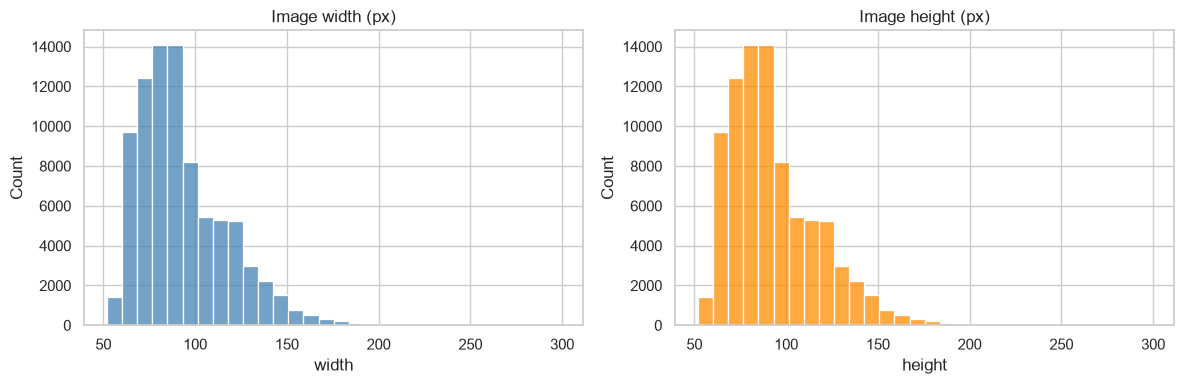

In [10]:
print('Colour modes:'); print(meta['mode'].value_counts().to_string())
print('\nFile formats:'); print(meta['format'].value_counts().to_string())
print('\nImage size summary:'); print(meta[['width', 'height']].describe().round(1).to_string())
print('\nDistinct sizes:', meta.groupby(['width', 'height']).ngroups)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(meta.width, bins=30, ax=ax[0], color='steelblue'); ax[0].set_title('Image width (px)')
sns.histplot(meta.height, bins=30, ax=ax[1], color='darkorange'); ax[1].set_title('Image height (px)')
plt.tight_layout(); savefig('clean_01_image_sizes.png'); plt.show()

## 6. Outliers
* **Blank / near-constant images**  no visible eye, so they are **removed**.
* **Tiny images**  too little detail, **removed**.
* **flagged but kept**. Very dark or very bright images are real lighting conditions (MRL has a "bad lighting" group) and the model must learn to handle them.

Brightness fence: [34.4, 132.9] -> 6025 flagged (kept)
Blank / near-constant images (std < 3.0 ): 0
Tiny images (min side < 20 ): 0


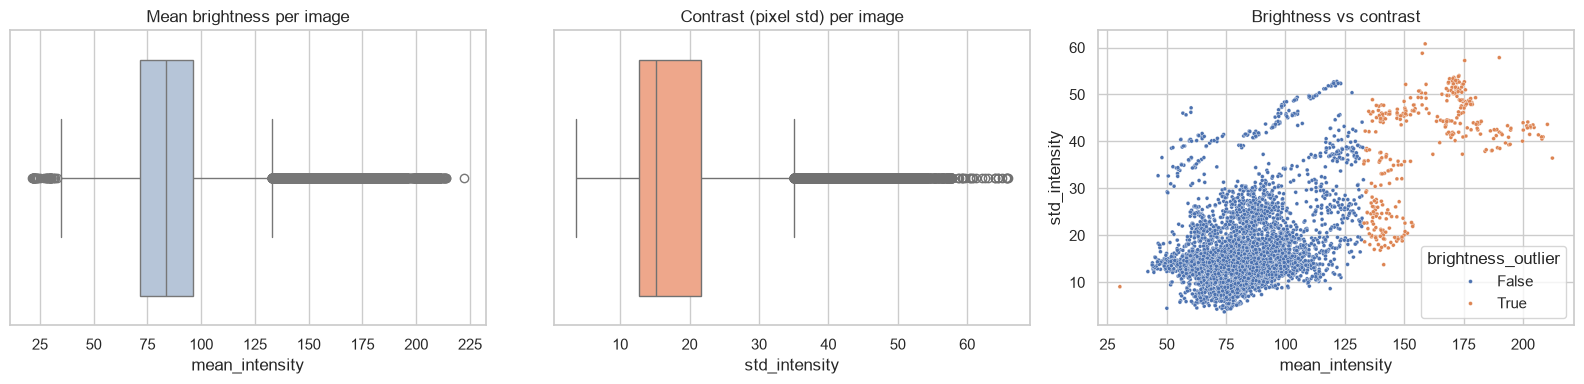

In [11]:
MIN_STD, MIN_SIDE = 3.0, 20

q1, q3 = meta.mean_intensity.quantile([.25, .75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
meta['brightness_outlier'] = (meta.mean_intensity < lo) | (meta.mean_intensity > hi)
print(f'Brightness fence: [{lo:.1f}, {hi:.1f}] -> {meta.brightness_outlier.sum()} flagged (kept)')
print('Blank / near-constant images (std <', MIN_STD, '):', (meta.std_intensity < MIN_STD).sum())
print('Tiny images (min side <', MIN_SIDE, '):', (meta[['width', 'height']].min(axis=1) < MIN_SIDE).sum())

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(x=meta.mean_intensity, ax=ax[0], color='lightsteelblue'); ax[0].set_title('Mean brightness per image')
sns.boxplot(x=meta.std_intensity, ax=ax[1], color='lightsalmon'); ax[1].set_title('Contrast (pixel std) per image')
sns.scatterplot(data=meta.sample(min(5000, len(meta)), random_state=0), x='mean_intensity', y='std_intensity',
                hue='brightness_outlier', s=8, ax=ax[2]); ax[2].set_title('Brightness vs contrast')
plt.tight_layout(); savefig('clean_02_outlier_boxplots.png'); plt.show()

In [12]:
bad = (meta.std_intensity < MIN_STD) | (meta[['width', 'height']].min(axis=1) < MIN_SIDE)
before = len(meta)
meta = meta[~bad].reset_index(drop=True)
log('Dropped blank / tiny images (outliers)', before - len(meta), len(meta))

Dropped blank / tiny images (outliers): removed 0, remaining 84827


## 7. Save the cleaned dataset and the cleaning log
We store the path **relative to `DATA_DIR`** so the table works on any machine.

In [13]:
meta['rel_path'] = meta.path.map(lambda p: os.path.relpath(p, DATA_DIR))
keep = ['rel_path', 'subject', 'image_id', 'gender', 'glasses', 'eye_state', 'reflections', 'lighting', 'sensor',
        'closed', 'width', 'height', 'mode', 'format', 'file_kb', 'mean_intensity', 'std_intensity', 'brightness_outlier']
clean = meta[keep].copy()
clean.to_csv(f'{PROC_DIR}/metadata_clean.csv', index=False)

log_df = pd.DataFrame(cleaning_log)
log_df.to_csv(f'{PROC_DIR}/cleaning_log.csv', index=False)
print('Final checks -> missing values:', int(clean.isna().sum().sum()),
      '| duplicate paths:', int(clean.rel_path.duplicated().sum()),
      '| labels:', sorted(clean.closed.unique()))
log_df

Final checks -> missing values: 0 | duplicate paths: 0 | labels: [np.int64(0), np.int64(1)]


,step,rows_removed,rows_remaining
0,Raw image files found,0,84898
1,Dropped malformed / missing / invalid-value fi...,0,84898
2,Dropped unreadable / corrupt images,0,84898
3,Dropped duplicate groups with conflicting labels,66,84832
4,Dropped duplicate images (kept first copy),5,84827
5,Dropped blank / tiny images (outliers),0,84827


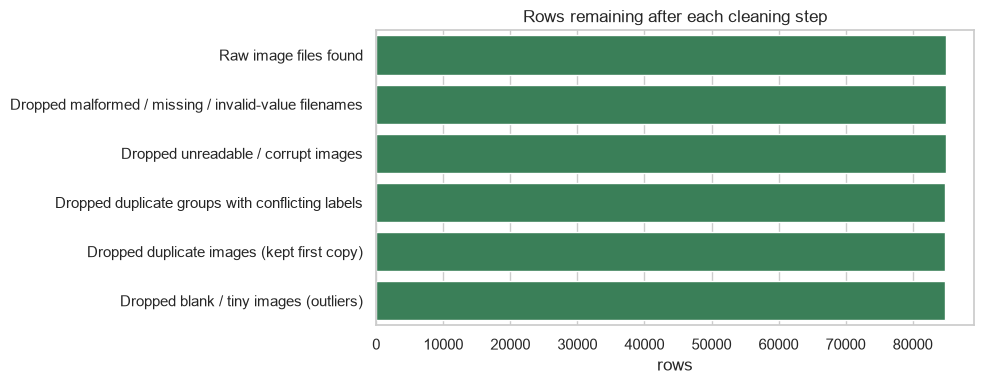

In [14]:
# Visual summary of the cleaning pipeline
steps = log_df[log_df.rows_remaining > 0]
plt.figure(figsize=(10, 4))
sns.barplot(data=steps, y='step', x='rows_remaining', color='seagreen')
plt.title('Rows remaining after each cleaning step'); plt.xlabel('rows'); plt.ylabel('')
plt.tight_layout(); savefig('clean_03_cleaning_pipeline.png'); plt.show()